In [254]:
import rasterio
import numpy as np, matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [255]:
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data"

IMAGES_DIR = DATA_DIR / "Browser_images"

### Loading spectral bands

In [256]:
bandes_spec_2021 =  {"B2_2021" : rasterio.open(IMAGES_DIR / "2021-08-11" / "2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B02_(Raw).tiff"),
"B3_2021" : rasterio.open(IMAGES_DIR / "2021-08-11" / "2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B03_(Raw).tiff"),
"B4_2021" : rasterio.open(IMAGES_DIR / "2021-08-11" / "2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B04_(Raw).tiff"),
"B8_2021" : rasterio.open(IMAGES_DIR / "2021-08-11" / "2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B08_(Raw).tiff",),
"B11_2021" : rasterio.open(IMAGES_DIR / "2021-08-11" / "2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B11_(Raw).tiff"),
"B12_2021" : rasterio.open(IMAGES_DIR / "2021-08-11" / "2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B12_(Raw).tiff")}

bandes_spec_2021

{'B2_2021': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2021-08-11\2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B02_(Raw).tiff' mode='r'>,
 'B3_2021': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2021-08-11\2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B03_(Raw).tiff' mode='r'>,
 'B4_2021': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2021-08-11\2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B04_(Raw).tiff' mode='r'>,
 'B8_2021': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2021-08-11\2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B08_(Raw).tiff' mode='r'>,
 'B11_2021': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2021-08-11\2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B11_(Raw).tiff' mode='r'>,
 'B12_2021': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2021-08-11\2021-08-11-00_00_2021-08-11-23_59_Sentinel-2_L2A_B12_(Raw).tiff' mode='r

In [257]:
bandes_spec_2026 =  {"B2_2026" : rasterio.open(IMAGES_DIR / "2026-08-05" / "2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B02_(Raw).tiff"),
"B3_2026" : rasterio.open(IMAGES_DIR / "2026-08-05" / "2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B03_(Raw).tiff"),
"B4_2026" : rasterio.open(IMAGES_DIR / "2026-08-05" / "2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B04_(Raw).tiff"),
"B8_2026" : rasterio.open(IMAGES_DIR / "2026-08-05" / "2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B08_(Raw).tiff",),
"B11_2026" : rasterio.open(IMAGES_DIR / "2026-08-05" / "2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B11_(Raw).tiff"),
"B12_2026" : rasterio.open(IMAGES_DIR / "2026-08-05" / "2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B12_(Raw).tiff")}

bandes_spec_2026

{'B2_2026': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2026-08-05\2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B02_(Raw).tiff' mode='r'>,
 'B3_2026': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2026-08-05\2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B03_(Raw).tiff' mode='r'>,
 'B4_2026': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2026-08-05\2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B04_(Raw).tiff' mode='r'>,
 'B8_2026': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2026-08-05\2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B08_(Raw).tiff' mode='r'>,
 'B11_2026': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2026-08-05\2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B11_(Raw).tiff' mode='r'>,
 'B12_2026': <open DatasetReader name='c:\Code\teledetection\data\Browser_images\2026-08-05\2026-08-05-00_00_2026-08-05-23_59_Sentinel-2_L2A_B12_(Raw).tiff' mode='r

### Data

#### 2021

In [258]:
data_bandes_2021 = {}
df_bandes_2021 = {}


for name, bande in bandes_spec_2021.items():
    data_bandes_2021[name] = bande.read(1)
    df_bandes_2021[name] = pd.DataFrame(data_bandes_2021[name]) #To visualize better the arrays representation of the images, pixel by pixel

data_bandes_2021["B8_2021"]
df_bandes_2021["B8_2021"].head(20) 

,0,1,2,3,4,5,6,7,8,9,...,494,495,496,497,498,499,500,501,502,503
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2852,0.2754,0.2496,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2868,0.2793,0.2503,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2558,0.2586,0.2487,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2513,0.2766,0.2578,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2478,0.2793,0.2606,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2318,0.2549,0.2557,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2363,0.2584,0.2593,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2476,0.2642,0.2671,...,0.2349,0.2135,0.2274,0.2474,0.2400,0.2225,0.2192,0.2386,0.2461,0.2750
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2570,0.2522,0.2623,...,0.2297,0.2045,0.1958,0.2157,0.2351,0.2253,0.2284,0.2665,0.2557,0.2773
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2743,0.2403,0.2514,...,0.2411,0.1990,0.1727,0.1980,0.2375,0.2337,0.2499,0.2909,0.2746,0.2720


#### 2026

In [259]:
data_bandes_2026 = {}
df_bandes_2026 = {}


for name, bande in bandes_spec_2026.items():
    data_bandes_2026[name] = bande.read(1)
    df_bandes_2026[name] = pd.DataFrame(data_bandes_2026[name]) #To visualize better the arrays representation of the images, pixel by pixel

data_bandes_2026["B8_2026"]
df_bandes_2026["B8_2026"].head(20) 

,0,1,2,3,4,5,6,7,8,9,...,494,495,496,497,498,499,500,501,502,503
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2822,0.2805,0.2565,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2751,0.2844,0.2673,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2540,0.2743,0.2617,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2483,0.2793,0.2665,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2371,0.2816,0.2799,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2256,0.2646,0.2625,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2288,0.2606,0.2643,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2466,0.2654,0.2710,...,0.2361,0.2191,0.2332,0.2589,0.2927,0.3345,0.2697,0.2432,0.2582,0.2830
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2588,0.2592,0.2596,...,0.2327,0.2045,0.1964,0.2230,0.2739,0.3059,0.2577,0.2493,0.2644,0.2891
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2618,0.2492,0.2445,...,0.2513,0.1953,0.1626,0.1935,0.2530,0.2685,0.2642,0.2620,0.2763,0.2865


### Affichage

In [260]:
from rasterio.plot import show, show_hist

#### 2021

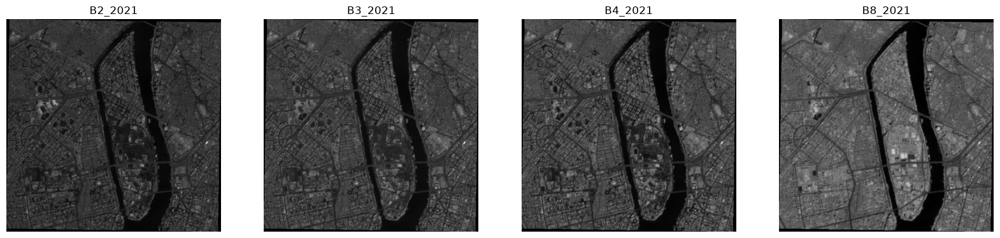

In [261]:
fig, axes = plt.subplots(1, 4, figsize=(20, 16))
for ax, nom in zip(axes, ("B2_2021", "B3_2021", "B4_2021", "B8_2021")):
    ax.imshow(bandes_spec_2021[nom].read(1), cmap="gray")
    ax.set_title(nom)
    ax.axis("off")
plt.show()

#### 2026

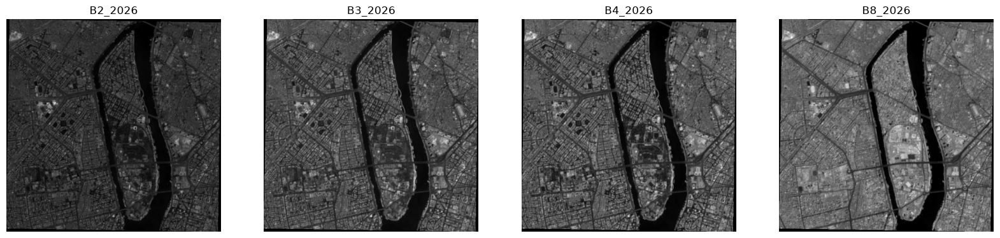

In [262]:
fig, axes = plt.subplots(1, 4, figsize=(20, 16))
for ax, nom in zip(axes, ("B2_2026", "B3_2026", "B4_2026", "B8_2026")):
    ax.imshow(bandes_spec_2026[nom].read(1), cmap="gray")
    ax.set_title(nom)
    ax.axis("off")
plt.show()

### Plot

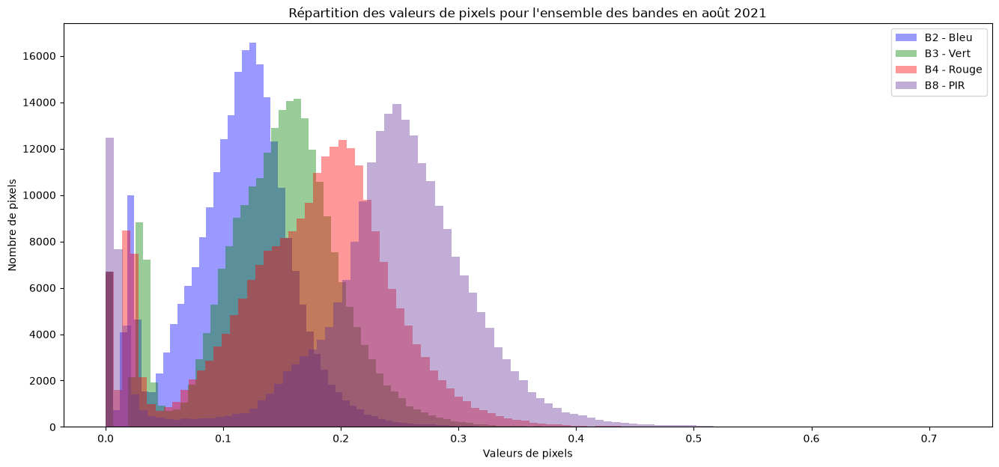

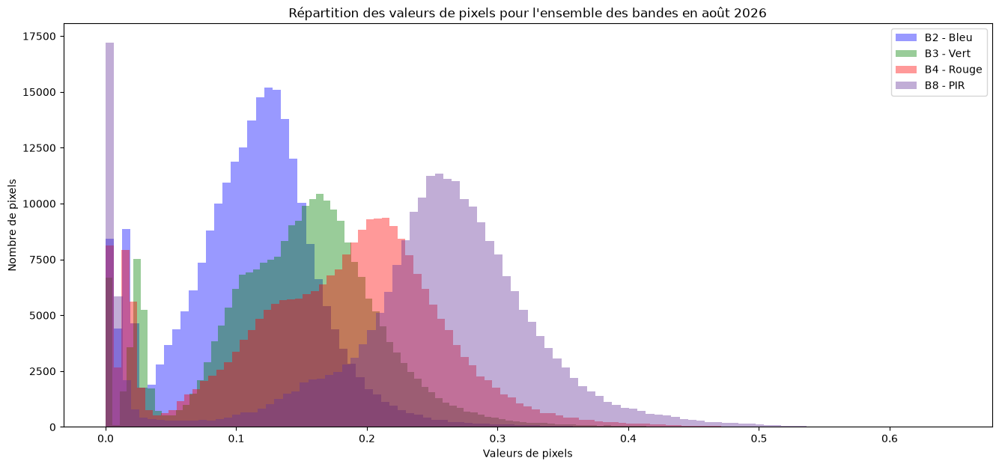

In [263]:
#2021
plt.figure(figsize=(16,7))

plt.hist(data_bandes_2021["B2_2021"].flatten(), bins=100, color="blue", alpha=0.4, label="B2 - Bleu")
plt.hist(data_bandes_2021["B3_2021"].flatten(), bins=100, color="green", alpha=0.4, label="B3 - Vert")
plt.hist(data_bandes_2021["B4_2021"].flatten(), bins=100, color="red", alpha=0.4, label="B4 - Rouge")
plt.hist(data_bandes_2021["B8_2021"].flatten(), bins=100, color="rebeccapurple", alpha=0.4, label="B8 - PIR")

plt.xlabel("Valeurs de pixels")
plt.ylabel("Nombre de pixels")
plt.title("Répartition des valeurs de pixels pour l'ensemble des bandes en août 2021")
plt.legend()


plt.show()

#2026
plt.figure(figsize=(16,7))

plt.hist(data_bandes_2026["B2_2026"].flatten(), bins=100, color="blue", alpha=0.4, label="B2 - Bleu")
plt.hist(data_bandes_2026["B3_2026"].flatten(), bins=100, color="green", alpha=0.4, label="B3 - Vert")
plt.hist(data_bandes_2026["B4_2026"].flatten(), bins=100, color="red", alpha=0.4, label="B4 - Rouge")
plt.hist(data_bandes_2026["B8_2026"].flatten(), bins=100, color="rebeccapurple", alpha=0.4, label="B8 - PIR")

plt.xlabel("Valeurs de pixels")
plt.ylabel("Nombre de pixels")
plt.title("Répartition des valeurs de pixels pour l'ensemble des bandes en août 2026")
plt.legend()


plt.show()

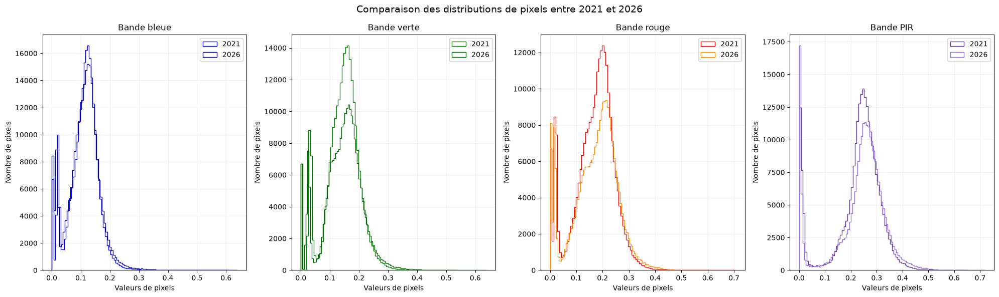

In [264]:
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

# Bleu
axes[0].hist(data_bandes_2021["B2_2021"].flatten(), histtype="step", bins=100, color="blue", label="2021")
axes[0].hist(data_bandes_2026["B2_2026"].flatten(), histtype="step", bins=100, color="darkblue", label="2026")
axes[0].set_title("Bande bleue")
axes[0].legend()

# Vert
axes[1].hist(data_bandes_2021["B3_2021"].flatten(), histtype="step", bins=100, color="green", label="2021")
axes[1].hist(data_bandes_2026["B3_2026"].flatten(), histtype="step", bins=100, color="darkgreen", label="2026")
axes[1].set_title("Bande verte")
axes[1].legend()

# Rouge
axes[2].hist(data_bandes_2021["B4_2021"].flatten(), histtype="step", bins=100, color="red", label="2021")
axes[2].hist(data_bandes_2026["B4_2026"].flatten(), histtype="step", bins=100, color="darkorange", label="2026")
axes[2].set_title("Bande rouge")
axes[2].legend()

# PIR
axes[3].hist(data_bandes_2021["B8_2021"].flatten(), histtype="step", bins=100, color="rebeccapurple", label="2021")
axes[3].hist(data_bandes_2026["B8_2026"].flatten(), histtype="step", bins=100, color="mediumpurple", label="2026")
axes[3].set_title("Bande PIR")
axes[3].legend()

# Mise en forme générale
for ax in axes:
    ax.set_xlabel("Valeurs de pixels")
    ax.set_ylabel("Nombre de pixels")
    ax.grid(alpha=0.2)

fig.suptitle("Comparaison des distributions de pixels entre 2021 et 2026", fontsize=14)
plt.tight_layout()
plt.show()

### Colorisation 

In [265]:
composites_2021 =  {"Natural colors (B4 - B3 - B2)" : ("B4_2021", "B3_2021", "B2_2021"),
               "Fausses couleurs (B8 - B4 - B3)" : ("B8_2021", "B4_2021", "B3_2021")}

composites_2026 =  {"Natural colors (B4 - B3 - B2)" : ("B4_2026", "B3_2026", "B2_2026"),
               "Fausses couleurs (B8 - B4 - B3)" : ("B8_2026", "B4_2026", "B3_2026")}

#### 2021

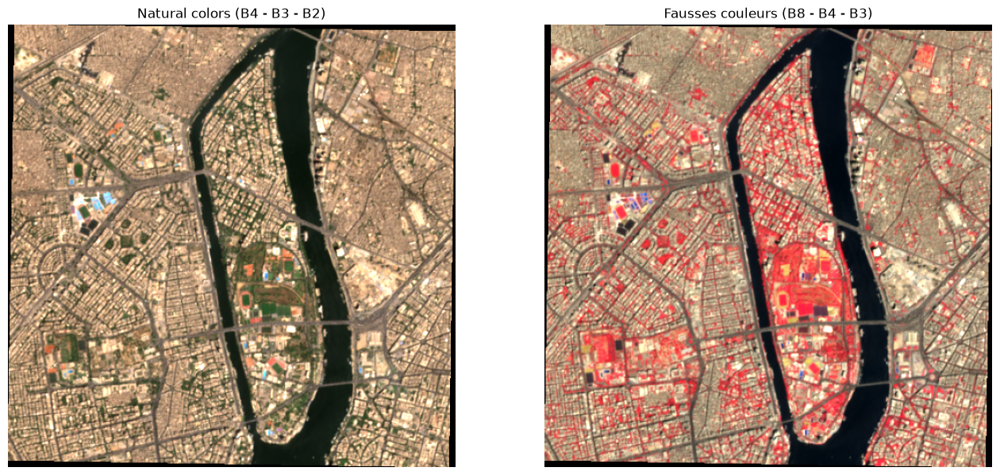

In [266]:
fig, axes = plt.subplots(1, 2, figsize=(16, 16))
for ax, (titre, (r, g, b)) in zip(axes, composites_2021.items()):
    rgb = np.dstack([data_bandes_2021[r], data_bandes_2021[g], data_bandes_2021[b]])
    p2, p98 = np.percentile(rgb, (2, 98))
    rgb = np.clip((rgb - p2) / (p98 - p2), 0, 1)
    ax.imshow(rgb)
    ax.set_title(titre)
    ax.axis("off")
plt.show()

#### 2026

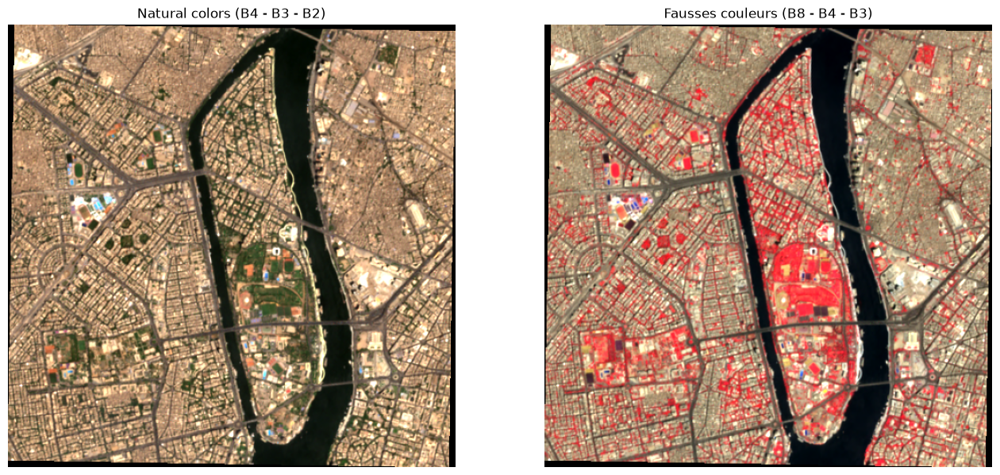

In [267]:
fig, axes = plt.subplots(1, 2, figsize=(16, 16))
for ax, (titre, (r, g, b)) in zip(axes, composites_2026.items()):
    rgb = np.dstack([data_bandes_2026[r], data_bandes_2026[g], data_bandes_2026[b]])
    p2, p98 = np.percentile(rgb, (2, 98))
    rgb = np.clip((rgb - p2) / (p98 - p2), 0, 1)
    ax.imshow(rgb)
    ax.set_title(titre)
    ax.axis("off")
plt.show()

### NDVI : B8 - B4 / B8 + B4

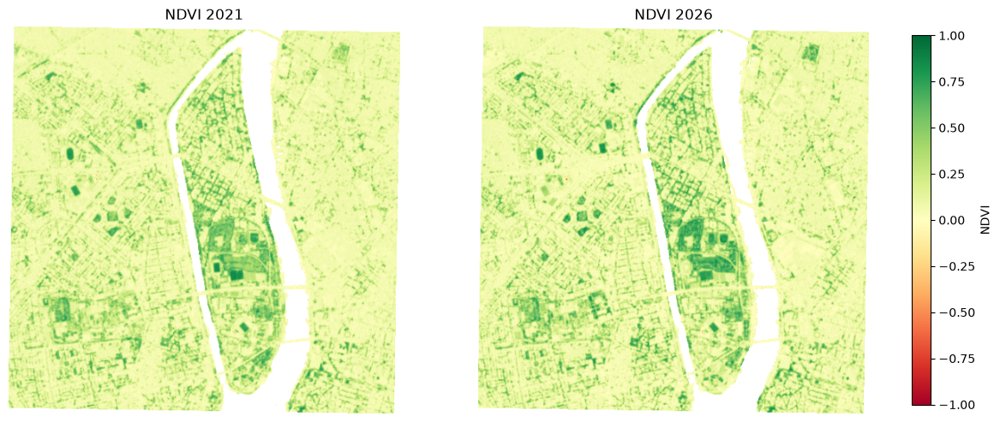

In [268]:
#2021
nir_2021 = bandes_spec_2021["B8_2021"].read(1)
masque_eau_2021 = nir_2021 < 0.05
red_2021 = bandes_spec_2021["B4_2021"].read(1)

ndvi_2021 = (nir_2021 - red_2021) / (nir_2021 + red_2021 + 1e-10)
ndvi_2021 = np.ma.masked_where(masque_eau_2021, ndvi_2021)

#2026
nir_2026 = bandes_spec_2026["B8_2026"].read(1)
masque_eau_2026 = nir_2026 < 0.05
red_2026 = bandes_spec_2026["B4_2026"].read(1)

ndvi_2026 = (nir_2026 - red_2026) / (nir_2026 + red_2026 + 1e-10)
ndvi_2026 = np.ma.masked_where(masque_eau_2026, ndvi_2026)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

im2021 = axes[0].imshow(ndvi_2021, cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_box_aspect(ndvi_2021.shape[0] / ndvi_2021.shape[1])
im2026 = axes[1].imshow(ndvi_2026, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_box_aspect(ndvi_2021.shape[0] / ndvi_2021.shape[1])

axes[0].set_title("NDVI 2021")
axes[1].set_title("NDVI 2026")
axes[0].axis("off")
axes[1].axis("off")

fig.colorbar(im2021, ax=axes.ravel().tolist(), label="NDVI", shrink=0.7, pad=0.04)


plt.show()

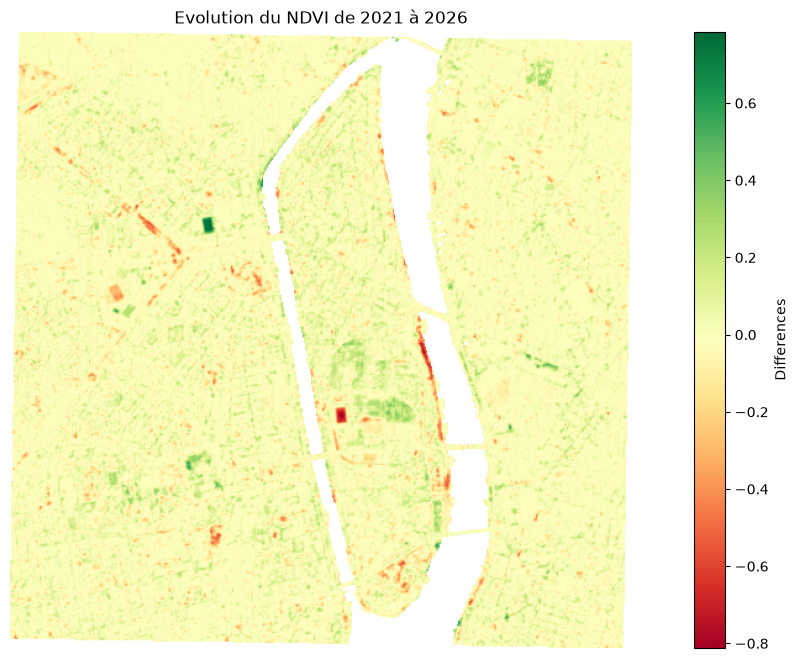

In [269]:
ndvi_diff = ndvi_2026 - ndvi_2021
fig, ax =  plt.subplots(figsize=(16, 8))
im = ax.imshow(ndvi_diff, cmap="RdYlGn", vmin=ndvi_diff.min(), vmax=ndvi_diff.max())
ax.axis("off")
ax.set_title("Evolution du NDVI de 2021 à 2026")
fig.colorbar(im, ax=ax, label="Differences")

plt.show()

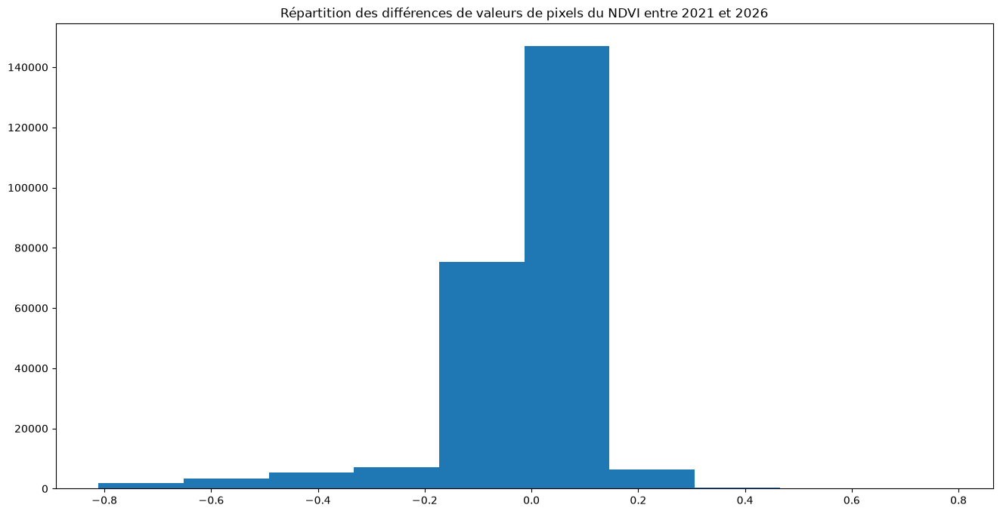

-0.0031690020114183426
0.0019368511
0.0741957


c:\Code\teledetection\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


In [305]:
plt.figure(figsize=(16, 8))

plt.hist(ndvi_diff.flatten())
plt.title("Répartition des différences de valeurs de pixels du NDVI entre 2021 et 2026")


plt.show()
print(np.nanmedian(ndvi_diff))
print(np.nanmean(ndvi_diff))
print(np.nanstd(ndvi_diff))

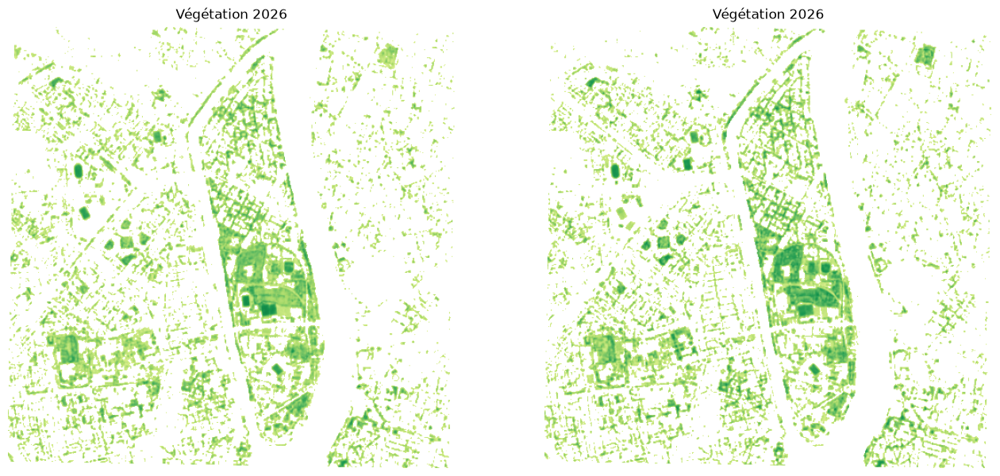

In [279]:
cairo_vege_2021 =  np.ma.masked_where(ndvi_2021 < 0.2, ndvi_2021)
cairo_vege_2026 = np.ma.masked_where(ndvi_2026 < 0.2, ndvi_2026)

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

im2021 = axes[0].imshow(cairo_vege_2021, cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_title("Végétation 2026")
axes[0].axis("off")

im2026 = axes[1].imshow(cairo_vege_2026, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("Végétation 2026")
axes[1].axis("off")

plt.show()

### NBI : B11 - B8 / B11 + B8

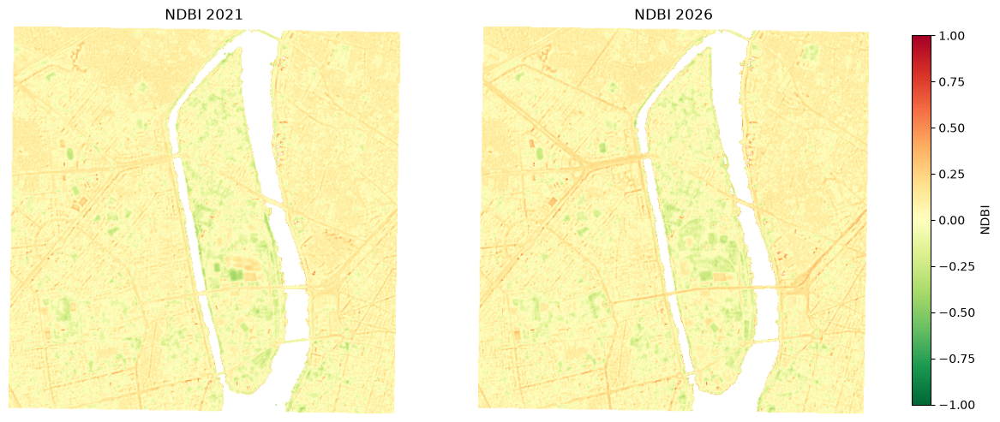

In [280]:
swir_2021 = bandes_spec_2021["B11_2021"].read(1)
swir_2026 = bandes_spec_2026["B11_2026"].read(1)

ndbi2021 = (swir_2021 - nir_2021) / (swir_2021 + nir_2021 + 1e-10)
ndbi2021 = np.ma.masked_where(masque_eau_2021, ndbi2021)
ndbi2026 = (swir_2026 - nir_2026) / (swir_2026 + nir_2026 + 1e-10)
ndbi2026 = np.ma.masked_where(masque_eau_2026, ndbi2026)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

im2021 = axes[0].imshow(ndbi2021, cmap="RdYlGn_r", vmin=-1, vmax=1)
axes[0].set_box_aspect(ndbi2021.shape[0] / ndbi2021.shape[1])
im2026 = axes[1].imshow(ndbi2026, cmap="RdYlGn_r", vmin=-1, vmax=1)
axes[1].set_box_aspect(ndbi2021.shape[0] / ndbi2026.shape[1])

axes[0].set_title("NDBI 2021")
axes[1].set_title("NDBI 2026")
axes[0].axis("off")
axes[1].axis("off")

fig.colorbar(im2021, ax=axes.ravel().tolist(), label="NDBI", shrink=0.7, pad=0.04)

plt.show()

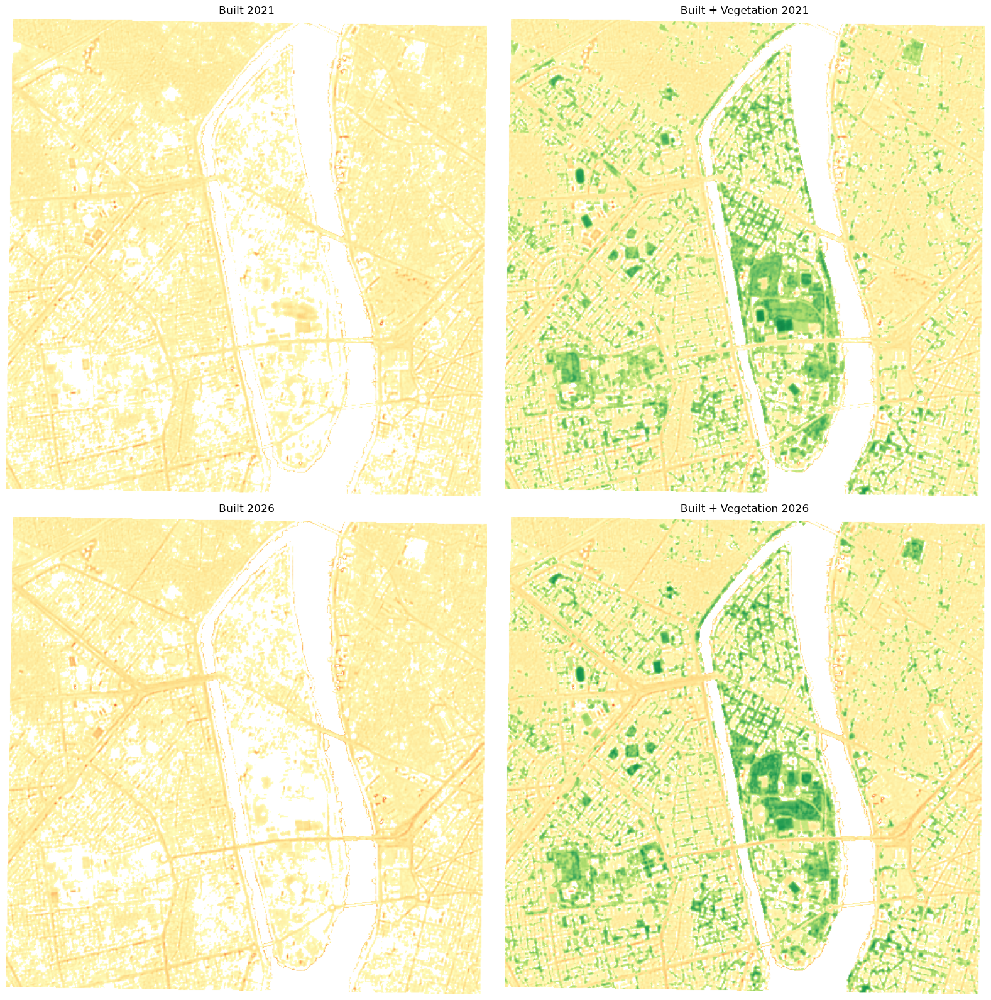

In [292]:
cairo_built_2021 = np.ma.masked_where(ndbi2021 <= 0, ndbi2021)
cairo_built_2026 = np.ma.masked_where(ndbi2026 <= 0, ndbi2026)

fig, axes = plt.subplots(2, 2, figsize=(16, 16))

axes[0, 0].imshow(cairo_built_2021, cmap="RdYlGn_r", vmin=-1, vmax=1)
axes[0, 0].set_title("Built 2021")
axes[0, 0].axis("off")

axes[0, 1].imshow(cairo_built_2021, cmap="RdYlGn_r", vmin=-1, vmax=1)
axes[0, 1].imshow(cairo_vege_2021, cmap="RdYlGn", vmin=-1, vmax=1)

axes[0, 1].set_title("Built + Vegetation 2021")
axes[0, 1].axis("off")

axes[1, 0].imshow(cairo_built_2026, cmap="RdYlGn_r", vmin=-1, vmax=1)
axes[1, 0].set_title("Built 2026")
axes[1, 0].axis("off")

axes[1, 1].imshow(cairo_built_2026, cmap="RdYlGn_r", vmin=-1, vmax=1)
axes[1, 1].imshow(cairo_vege_2026, cmap="RdYlGn", vmin=-1, vmax=1)

axes[1, 1].set_title("Built + Vegetation 2026")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

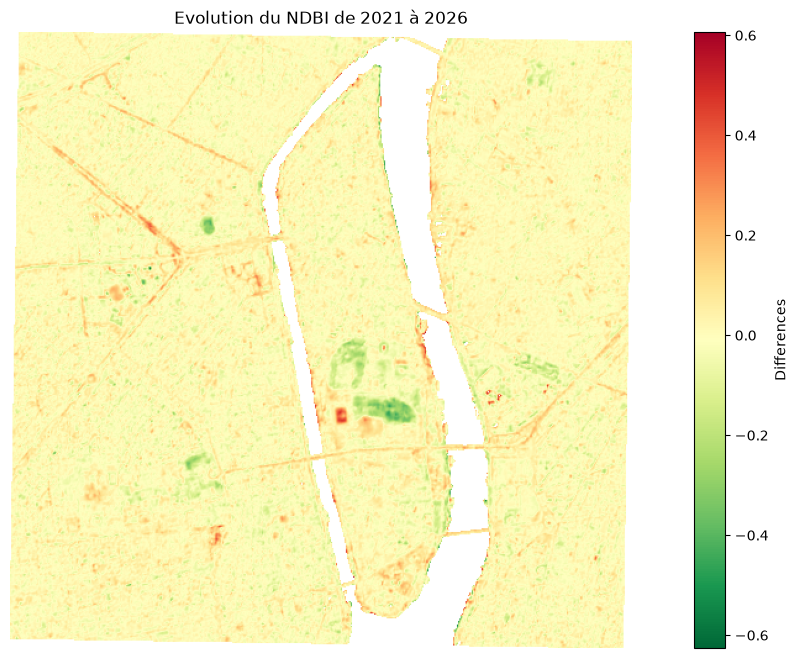

In [294]:
ndbi_diff = ndbi2026 - ndbi2021
fig, ax =  plt.subplots(figsize=(16, 8))
im = ax.imshow(ndbi_diff, cmap="RdYlGn_r", vmin=ndbi_diff.min(), vmax=ndbi_diff.max())
ax.axis("off")
ax.set_title("Evolution du NDBI de 2021 à 2026")
fig.colorbar(im, ax=ax, label="Differences")

plt.show()

### Typologie de l'évolution

In [341]:
# NDWI sur chaque date (adapte les noms de variables aux tiens)
ndwi_2026 = (data_bandes_2026["B3_2026"] - data_bandes_2026["B8_2026"]) / (data_bandes_2026["B3_2026"] + data_bandes_2026["B8_2026"] + 1e-10)
ndwi_2021 = (data_bandes_2021["B3_2021"] - data_bandes_2021["B8_2021"]) / (data_bandes_2021["B3_2021"] + data_bandes_2021["B8_2021"] + 1e-10)

# eau = pixel d'eau sur au moins une des deux dates
masque_eau = (ndwi_2026 > 0) | (ndwi_2021 > 0)

ndvi_diff = ndvi_diff.copy()
ndvi_diff[masque_eau] = np.nan

In [342]:
med = np.nanmedian(ndvi_diff)
sig = 1.4826 * np.nanmedian(np.abs(ndvi_diff - med))   # MAD ramené à l'échelle d'un écart-type

seuils = {1: (-np.inf, med - 2*sig),
          2: (med - 2*sig, med - 1*sig),
          3: (med - 1*sig, med + 1*sig),
          4: (med + 1*sig, med + 2*sig),
          5: (med + 2*sig, np.inf)}
noms = {1: "Perte forte", 2: "Perte faible", 3: "Stable", 4: "Gain faible", 5: "Gain fort"}

classes = np.full(ndvi_diff.shape, np.nan)
for code, (bas, haut) in seuils.items():
    classes[(ndvi_diff >= bas) & (ndvi_diff < haut)] = code

n_valides = np.sum(~np.isnan(classes))
print(f"médiane = {med:.3f} | sigma robuste = {sig:.3f}")
for code, nom in noms.items():
    n = np.sum(classes == code)
    print(f"{nom:13s} {n * 100 / 1e6:.2f} km² ({n / n_valides * 100:.1f} %)")

médiane = 0.000 | sigma robuste = 0.035
Perte forte   1.76 km² (7.7 %)
Perte faible  2.12 km² (9.2 %)
Stable        14.35 km² (62.5 %)
Gain faible   2.26 km² (9.9 %)
Gain fort     2.45 km² (10.7 %)


c:\Code\teledetection\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4028: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  part.partition(kth)


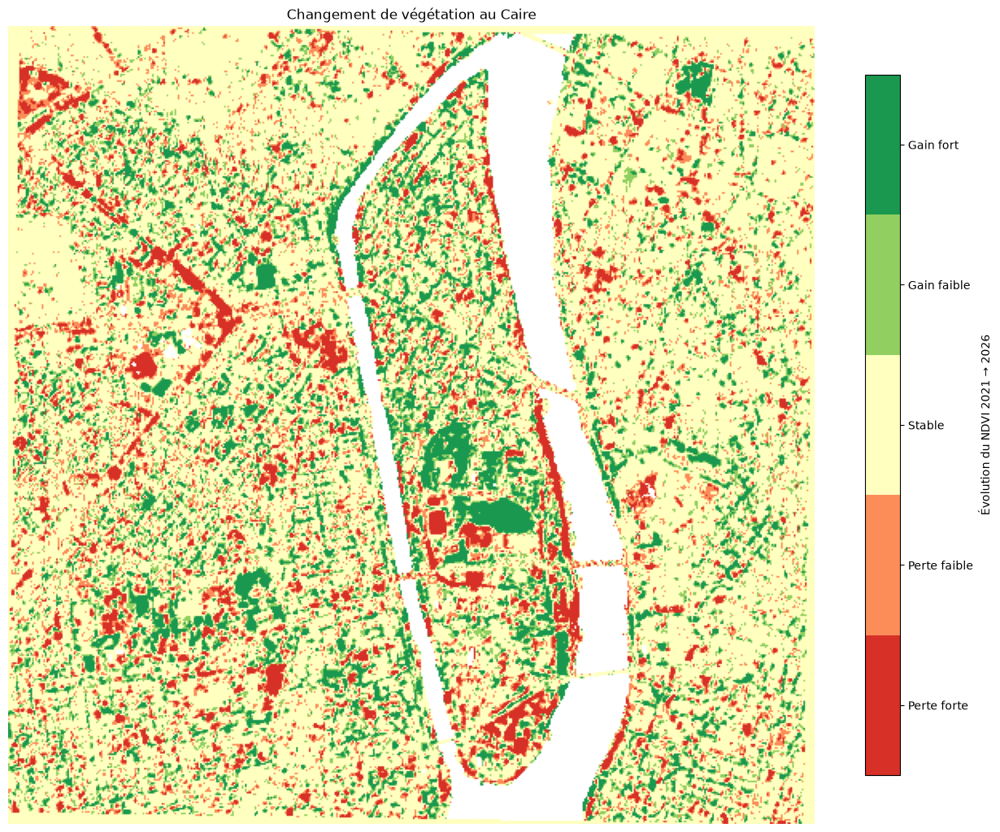

In [353]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#d73027", "#fc8d59", "#ffffbf", "#91cf60", "#1a9850"])
cmap.set_bad("white")   # eau et pixels masqués

fig, ax = plt.subplots(figsize=(16, 16))
im = ax.imshow(classes, cmap=cmap, vmin=0.5, vmax=5.5)
cbar = plt.colorbar(im, ax=ax, ticks=[1, 2, 3, 4, 5], shrink=0.7)
cbar.ax.set_yticklabels(list(noms.values()))
cbar.set_label("Évolution du NDVI 2021 → 2026")
ax.set_title("Changement de végétation au Caire")
ax.axis("off")
plt.show()